# Lesson 9. Grover's algorithm

**Goal:** understand Grover with matrices in $\mathbb{C}^8$: what the oracle is, what diffusion is, why the secret has 94.5% after two iterations but only 33% after three, and where the $\sqrt N$ instead of $N$ speedup comes from. This is the mathematics behind Demo 1 of the talk.

## 1. The problem

We have a function $f: \{0, \dots, N-1\} \to \{0, 1\}$ with exactly one $w$ such that $f(w) = 1$. We know nothing about the structure of $f$: we can only call it ("is this the password?").

- Classically this takes $N/2$ calls on average and $N - 1$ in the worst case (the last candidate need not be checked).
- The cost of the algorithm is counted **in calls to $f$**. In the quantum version one call to $f$ is one use of the oracle.

In the demo $N = 8$ (3 qubits) and $w$ is the number the audience picks. In the examples below $w = 5$, label 101, i.e. the vector $e_5 \in \mathbb{C}^8$.

## 2. The space and the initial state

The state of 3 qubits is a unit vector $v \in \mathbb{C}^8$: eight coordinates, one amplitude for each outcome 000, ..., 111 (lesson 6).

> **This was tricky:** "each qubit is in state 0 or 1" is a shortcut that leads the wrong way. The **measurement outcome** of each qubit is 0 or 1, hence $2^3 = 8$ possible outcomes. The **state** is any unit vector in $\mathbb{C}^8$. The eight "classical" states are just the basis vectors $e_0, \dots, e_7$, and Grover works precisely with vectors that are **not** basis vectors.

We start from $e_0 = e_0 \otimes e_0 \otimes e_0$ (the cooled chip). The same symbol $e_0$ denotes a basis vector of $\mathbb{C}^8$ on the left and of $\mathbb{C}^2$ on the right; the context always tells which. A Hadamard on each qubit, i.e. the matrix $H \otimes H \otimes H$ (lesson 5), gives

$$u = (H \otimes H \otimes H)\, e_0 = He_0 \otimes He_0 \otimes He_0 = \tfrac{1}{\sqrt8}(1, 1, 1, 1, 1, 1, 1, 1).$$

All amplitudes equal $a = 1/\sqrt8 \approx 0.354$, every outcome has $P = 1/8$.

> **This was tricky:** a quantum computer does **not** "check all 8 answers at once". If we measured $u$ we would get a random number, i.e. plain guessing. The equal superposition is only the starting point; all the work is done by interference in the following steps.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
GREEN, DARK, LIGHT, GREY, ORANGE = "#44B749", "#1A8A1F", "#96E199", "#8A8A8A", "#E08A00"

e0 = np.array([1, 0], dtype=complex)   # label |0⟩
e1 = np.array([0, 1], dtype=complex)   # label |1⟩

def norm(v):
    return np.sqrt(np.sum(np.abs(v) ** 2))

def show(v, n=None):
    """Print a state vector with bit labels (label = position written in binary)."""
    v = np.asarray(v)
    n = n or int(np.log2(len(v)))
    for k, a in enumerate(v):
        if abs(a) > 1e-12:
            print(f"  position {k} ({format(k, f'0{n}b')}): amplitude {np.round(a, 3)}, P = {abs(a)**2:.3f}")

from functools import reduce
from fractions import Fraction
kron = lambda *ms: reduce(np.kron, ms)

n, N, w = 3, 8, 5
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
X = np.array([[0, 1], [1, 0]])
I2 = np.eye(2)
H3 = kron(H, H, H)          # an 8×8 matrix
E = np.eye(N)               # E[k] is the basis vector e_k

u = H3 @ E[0]
print("u =", u)
print("P =", np.abs(u) ** 2)

u = [0.354 0.354 0.354 0.354 0.354 0.354 0.354 0.354]
P = [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]

## 3. The oracle: a diagonal matrix

$$O = I - 2\, e_w e_w^{T} = \operatorname{diag}(1, 1, 1, 1, 1, -1, 1, 1) \qquad (w = 5).$$

On basis vectors: $O e_x = (-1)^{f(x)} e_x$. By linearity, for any state $v$ the oracle flips the sign of **one** coordinate, $v_w$, and nothing else.

- $O$ is unitary (diagonal with $\pm 1$) and is its own inverse.
- **Probabilities do not change**: $|-v_w|^2 = |v_w|^2$. This is the relative phase from lesson 3: measurement cannot see it. The oracle alone, even used a hundred times, gives no information. The phase is "seen" only by the next step, diffusion.

In [2]:
O = E - 2 * np.outer(E[w], E[w])
print("diagonal of O:", np.diag(O))
print("O unitary:", np.allclose(O.T @ O, E))

v = O @ u
print("O u       =", v)
print("P after O =", np.abs(v) ** 2, " <- unchanged")

diagonal of O: [ 1.  1.  1.  1.  1. -1.  1.  1.]
O unitary: True
O u       = [ 0.354  0.354  0.354  0.354  0.354 -0.354  0.354  0.354]
P after O = [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]  <- unchanged

### Building the oracle from gates

The CCZ gate flips the sign only at 111: $\mathrm{CCZ} = \operatorname{diag}(1, \dots, 1, -1)$. To flip the sign at any $w$, we temporarily "repaint" $w$ as 111: put $X$ on the qubits where $w$ has a 0 bit.

$$O = X_S \cdot \mathrm{CCZ} \cdot X_S, \qquad S = \{\text{qubits where } w \text{ has a } 0\}.$$

For $w = 101$: $X_S = I \otimes X \otimes I$. Then $e_5 \xrightarrow{X} e_7 \xrightarrow{\mathrm{CCZ}} -e_7 \xrightarrow{X} -e_5$, while e.g. $e_7 \xrightarrow{X} e_5 \xrightarrow{\mathrm{CCZ}} e_5 \xrightarrow{X} e_7$.

This is how the oracle is built in `00_ibm.ipynb`. In PennyLane a single gate does it, `qml.FlipSign`. (CCZ itself is $H$ on the third qubit, a Toffoli, then $H$ again, because $HXH = Z$.)

**Watch the bit order:** below, as in PennyLane, qubit 0 is the **first** bit. Qiskit numbers them the other way round, which is why the indices are reversed in `00_ibm`.

In [3]:
CCZ = np.diag([1, 1, 1, 1, 1, 1, 1, -1])

def X_on(qubits):
    """X on the given qubits, I on the others (qubit 0 = first bit)."""
    return kron(*[X if q in qubits else I2 for q in range(n)])

for s in range(N):
    bits = format(s, "03b")
    zeros = [q for q in range(n) if bits[q] == "0"]
    O_s = X_on(zeros) @ CCZ @ X_on(zeros)
    assert np.allclose(O_s, E - 2 * np.outer(E[s], E[s]))
print("X_S · CCZ · X_S = I − 2 e_s e_sᵀ for all 8 secrets")

X_S · CCZ · X_S = I − 2 e_s e_sᵀ for all 8 secrets

### A real oracle doesn't know the answer

> **This was tricky:** in the demo we build the oracle **knowing** $w$. That is a shortcut. In a real problem the oracle is a circuit that **checks** a candidate, e.g. computes a hash and compares it with the stored one. It does not know $w$, it can only recognise it.

Such a circuit computes $f$ into an extra qubit (reversibly, since gates are unitary):

$$U_f\,(e_x \otimes e_y) = e_x \otimes e_{y \oplus f(x)}.$$

If the extra qubit is set to $m = (e_0 - e_1)/\sqrt2$, adding $f(x)$ turns into multiplying by $(-1)^{f(x)}$:

$$U_f\,(e_x \otimes m) = (-1)^{f(x)}\,(e_x \otimes m).$$

This is **phase kickback**: the sign "kicks back" onto the data qubits and the extra qubit is unchanged. We get the same matrix $O$. (In practice the intermediate results of computing $f$ must also be uncomputed, so one oracle call costs roughly two evaluations of $f$.) That is why one use of the oracle is one full evaluation of $f$, e.g. a hash, on a quantum computer.

In [4]:
f = lambda x: int(x == w)
Uf = np.zeros((2 * N, 2 * N))
for x in range(N):
    for y in range(2):
        Uf[2 * x + (y ^ f(x)), 2 * x + y] = 1    # e_x ⊗ e_y = e_(2x+y)
print("U_f is a permutation (unitary):", np.allclose(Uf.T @ Uf, np.eye(2 * N)))

m = np.array([1, -1]) / np.sqrt(2)
for x in range(N):
    vx = kron(E[x], m)
    sign = (Uf @ vx) @ vx
    print(f"x = {x} ({x:03b}):  U_f (e_x ⊗ m) = {sign:+.0f} · (e_x ⊗ m)")

U_f is a permutation (unitary): True
x = 0 (000):  U_f (e_x ⊗ m) = +1 · (e_x ⊗ m)
x = 1 (001):  U_f (e_x ⊗ m) = +1 · (e_x ⊗ m)
x = 2 (010):  U_f (e_x ⊗ m) = +1 · (e_x ⊗ m)
x = 3 (011):  U_f (e_x ⊗ m) = +1 · (e_x ⊗ m)
x = 4 (100):  U_f (e_x ⊗ m) = +1 · (e_x ⊗ m)
x = 5 (101):  U_f (e_x ⊗ m) = -1 · (e_x ⊗ m)
x = 6 (110):  U_f (e_x ⊗ m) = +1 · (e_x ⊗ m)
x = 7 (111):  U_f (e_x ⊗ m) = +1 · (e_x ⊗ m)

## 4. Diffusion: reflection about the mean

$$D = 2\,u u^{T} - I.$$

On coordinates it is very simple. If $\bar v$ is the mean of the coordinates of $v$, then $u u^T v = \bar v \cdot (1, \dots, 1)$, so

$$(Dv)_k = 2\bar v - v_k.$$

Every coordinate is reflected about the mean. The key observation: a coordinate far **below** the mean (the one whose sign the oracle flipped) lands far **above** it. Diffusion turns a phase, which measurement cannot see, into a difference in magnitudes, which it can.

As a circuit: $D = H^{\otimes 3}\,(2 e_0 e_0^{T} - I)\,H^{\otimes 3}$, because $H^{\otimes 3} e_0 = u$ and $H^{\otimes 3}$ is its own inverse. In PennyLane this is `qml.GroverOperator`.

In [5]:
D = 2 * np.outer(u, u) - E
print("D = H3 (2 e0 e0ᵀ − I) H3:", np.allclose(D, H3 @ (2 * np.outer(E[0], E[0]) - E) @ H3))
print("D unitary:", np.allclose(D.T @ D, E))

v = np.array([1, 2, 3, 4, 5, 6, 7, 8.0])
print("\nv          =", v, " mean =", v.mean())
print("D v        =", D @ v)
print("2·mean − v =", 2 * v.mean() - v)

D = H3 (2 e0 e0ᵀ − I) H3: True
D unitary: True

v          = [1. 2. 3. 4. 5. 6. 7. 8.]  mean = 4.5
D v        = [8. 7. 6. 5. 4. 3. 2. 1.]
2·mean − v = [8. 7. 6. 5. 4. 3. 2. 1.]

## 5. Computing by hand for $N = 8$

One Grover iteration is $G = D\,O$. Let $a = 1/\sqrt8$. By symmetry two numbers suffice: the amplitude of each of the 7 wrong answers and the amplitude of the secret.

| | other 7 | secret | mean | $P(w)$ |
|---|---|---|---|---|
| start | $a$ | $a$ | | $1/8 = 0.125$ |
| after $O$ | $a$ | $-a$ | $3a/4$ | |
| after $D$ ($k = 1$) | $a/2$ | $5a/2$ | | $25/32 = 0.781$ |
| after $O$ | $a/2$ | $-5a/2$ | $a/8$ | |
| after $D$ ($k = 2$) | $-a/4$ | $11a/4$ | | $121/128 = 0.945$ |
| after $O$ | $-a/4$ | $-11a/4$ | $-9a/16$ | |
| after $D$ ($k = 3$) | $-7a/8$ | $13a/8$ | | $169/512 = 0.330$ |

Norm check for $k = 1$: $7 \cdot \tfrac14 \cdot \tfrac18 + \tfrac{25}{32} = \tfrac{7}{32} + \tfrac{25}{32} = 1$.

- Each iteration "pours" amplitude from the seven wrong answers into the secret.
- At $k = 2$ the wrong amplitudes cross zero ($-a/4$). At $k = 3$ the mean is already negative, the reflection works the other way and the secret's amplitude drops. This is "More is not better" from the notebook.

k = 0:  others =     1 · a,  secret =     1 · a,  P(secret) = 0.125
k = 1:  others =   1/2 · a,  secret =   5/2 · a,  P(secret) = 0.781
k = 2:  others =  -1/4 · a,  secret =  11/4 · a,  P(secret) = 0.945
k = 3:  others =  -7/8 · a,  secret =  13/8 · a,  P(secret) = 0.330

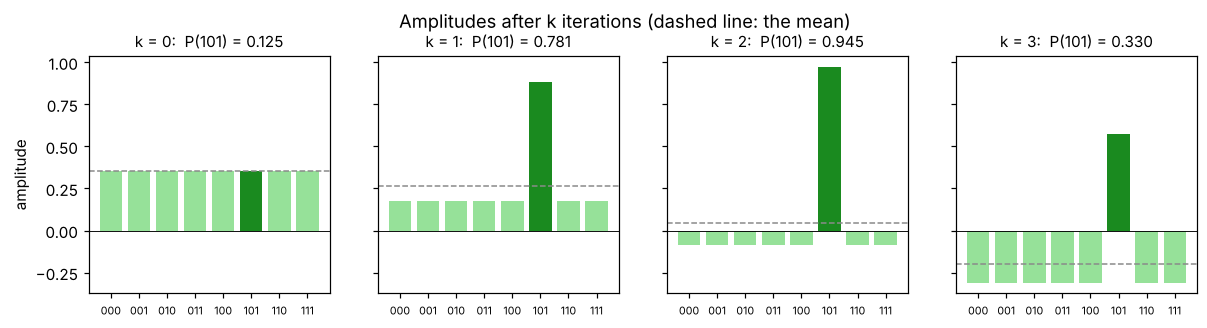

In [6]:
a = 1 / np.sqrt(N)
G = D @ O
v, states = u.copy(), []
for k in range(4):
    states.append(v.copy())
    other, sec = Fraction(v[0] / a).limit_denominator(64), Fraction(v[w] / a).limit_denominator(64)
    print(f"k = {k}:  others = {str(other):>5} · a,  secret = {str(sec):>5} · a,  P(secret) = {v[w] ** 2:.3f}")
    v = G @ v

fig, axs = plt.subplots(1, 4, figsize=(13, 2.8), sharey=True)
labels = [format(k, "03b") for k in range(N)]
for k, (ax, s) in enumerate(zip(axs, states)):
    ax.bar(labels, s, color=[DARK if j == w else LIGHT for j in range(N)])
    ax.axhline(s.mean(), color=GREY, ls="--", lw=1)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"k = {k}:  P(101) = {s[w] ** 2:.3f}", fontsize=10)
    ax.tick_params(axis="x", labelsize=7)
axs[0].set_ylabel("amplitude")
fig.suptitle("Amplitudes after k iterations (dashed line: the mean)", y=1.03)

## 6. Geometry: two reflections make a rotation

The state never leaves the plane spanned by two orthonormal vectors:

- $e_w$: the secret,
- $r = \frac{1}{\sqrt{N-1}} \sum_{k \ne w} e_k$: the equal superposition of the wrong answers.

The initial state lies in this plane at a small angle $\theta$ from $r$:

$$u = \sin\theta\; e_w + \cos\theta\; r, \qquad \sin\theta = \frac{1}{\sqrt N}.$$

For $N = 8$: $\theta = \arcsin(1/\sqrt8) \approx 20.7^\circ$.

In this plane both matrices are **reflections**:

- $O$ flips the component along $e_w$ and leaves $r$: a reflection about the line $r$;
- $D$ leaves $u$ ($Du = 2u - u = u$) and flips any vector perpendicular to $u$: a reflection about the line $u$.

Composing two reflections about lines that meet at angle $\theta$ gives a **rotation by $2\theta$** (a fact from plane geometry). After $k$ iterations the state is at angle $(2k+1)\theta$ from $r$:

$$G^k u = \sin\big((2k+1)\theta\big)\, e_w + \cos\big((2k+1)\theta\big)\, r, \qquad P(w) = \sin^2\big((2k+1)\theta\big).$$

Check against the table: $\sin 3\theta = 3\sin\theta - 4\sin^3\theta = \tfrac{3}{\sqrt8} - \tfrac{4}{8\sqrt8} = \tfrac{5}{2\sqrt8} = 5a/2$. It matches.

In [7]:
r = (np.ones(N) - E[w]) / np.sqrt(N - 1)
theta = np.arcsin(1 / np.sqrt(N))
print(f"θ = {np.degrees(theta):.1f}°")
print("u = sinθ e_w + cosθ r:", np.allclose(u, np.sin(theta) * E[w] + np.cos(theta) * r))

B = np.column_stack([r, E[w]])          # basis of the plane: r as the x axis, e_w as the y axis
G2 = B.T @ G @ B                        # G restricted to the plane: a 2×2 matrix
R = np.array([[np.cos(2 * theta), -np.sin(2 * theta)],
              [np.sin(2 * theta),  np.cos(2 * theta)]])
print("G in the plane:\n", G2)
print("rotation by 2θ:\n", R)
print("equal:", np.allclose(G2, R))

θ = 20.7°
u = sinθ e_w + cosθ r: True
G in the plane:
 [[ 0.75  -0.661]
 [ 0.661  0.75 ]]
rotation by 2θ:
 [[ 0.75  -0.661]
 [ 0.661  0.75 ]]
equal: True

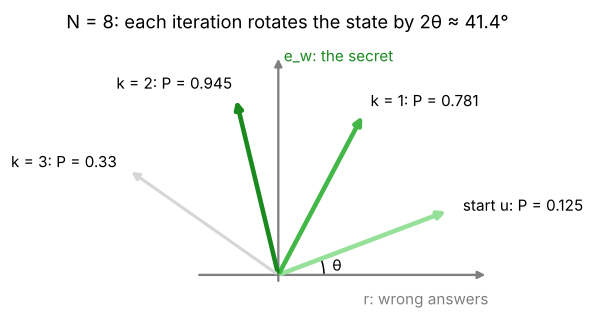

In [8]:
fig, ax = plt.subplots(figsize=(6, 5.4))
ax.set_aspect("equal"); ax.axis("off")
ax.annotate("", xy=(1.15, 0), xytext=(-0.45, 0), arrowprops=dict(arrowstyle="-|>", color="grey", lw=1.5))
ax.annotate("", xy=(0, 1.2), xytext=(0, -0.05), arrowprops=dict(arrowstyle="-|>", color="grey", lw=1.5))
ax.text(1.15, -0.08, "r: wrong answers", ha="right", va="top", color="grey")
ax.text(0.03, 1.2, "e_w: the secret", va="center", color=DARK)
shades = [LIGHT, GREEN, DARK, "#D6D6D6"]
for k in range(4):
    ang = (2 * k + 1) * theta
    ax.annotate("", xy=(np.cos(ang), np.sin(ang)), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=shades[k], lw=3 if k < 3 else 2))
    label = "start u" if k == 0 else f"k = {k}"
    ax.text(1.08 * np.cos(ang), 1.08 * np.sin(ang), f"{label}: P = {np.sin(ang) ** 2:.3g}",
            ha="left" if np.cos(ang) > 0.1 else "right", va="center", fontsize=10)
t = np.linspace(0, theta, 30)
ax.plot(0.25 * np.cos(t), 0.25 * np.sin(t), color="black", lw=1)
ax.text(0.3 * np.cos(theta / 2), 0.3 * np.sin(theta / 2), "θ", va="center")
ax.set_xlim(-1.35, 1.45); ax.set_ylim(-0.15, 1.3)
ax.set_title("N = 8: each iteration rotates the state by 2θ ≈ 41.4°")

## 7. Where $\sqrt N$ comes from

To reach $e_w$ the state has to turn by about $90^\circ$: $(2k+1)\theta \approx \pi/2$, so

$$k \approx \frac{\pi}{4\theta} - \frac12 \approx \frac{\pi}{4}\sqrt N,$$

because for large $N$ we have $\theta \approx \sin\theta = 1/\sqrt N$. The number of steps grows like $\sqrt N$ instead of $N$: a **quadratic speedup**.

- **This is optimal.** For unstructured search no quantum algorithm can do it in fewer than order $\sqrt N$ calls (Bennett, Bernstein, Brassard, Vazirani 1997). So Grover does not break everything "exponentially faster".
- **You have to know when to stop.** The optimal $k$ depends on $N$ (and on the number of solutions $M$: then $\sin\theta = \sqrt{M/N}$). Too many iterations rotate past the target.
- **Steps are not time.** For the password on slide 9 ($26^{10} \approx 1.4 \cdot 10^{14}$) it is about 9.3 million iterations, but each is a full hash evaluation on an error-corrected quantum computer, run one after another. Grover barely parallelises ($K$ machines give only $\sqrt K$). A GPU checks billions of passwords per second and wins in this example.

In [9]:
print(f"{'N':>22} {'classical (worst case)':>24} {'optimal k':>12} {'P(w)':>7}")
for label, NN in [("8", 8), ("64", 64), ("1024", 1024), ("1 million", 10 ** 6), ("26^10", 26 ** 10)]:
    th = np.arcsin(1 / np.sqrt(float(NN)))
    k = int(np.floor(np.pi / (4 * th)))
    print(f"{label:>22} {float(NN):>24.3g} {k:>12,} {np.sin((2 * k + 1) * th) ** 2:>7.3f}")

                     N   classical (worst case)    optimal k    P(w)
                     8                        8            2   0.945
                    64                       64            6   0.997
                  1024                 1.02e+03           25   0.999
             1 million                    1e+06          785   1.000
                 26^10                 1.41e+14    9,331,610   1.000

## 8. On real hardware

A noiseless simulator gives exactly $121/128 \approx 94.5\%$ for $k = 2$. On ibm_marrakesh (27 November 2026, 1,000 shots for each of the 8 possible secrets) the secret came up 758 to 820 times out of 1,000. After transpiling, the circuit has 45 two-qubit gates, and each adds a bit of noise (lesson 5: hardware is not a closed system). Still, the secret stands out clearly: the second most frequent answer has at most 65 hits.

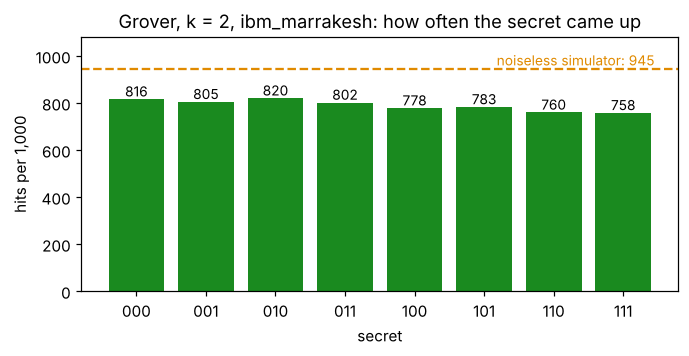

In [10]:
ibm = {0: 816, 1: 805, 2: 820, 3: 802, 4: 778, 5: 783, 6: 760, 7: 758}
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([format(s, "03b") for s in ibm], ibm.values(), color=DARK)
ax.axhline(1000 * 121 / 128, color=ORANGE, ls="--")
ax.text(7.45, 960, "noiseless simulator: 945", ha="right", color=ORANGE, fontsize=9)
for i, c in enumerate(ibm.values()):
    ax.text(i, c + 12, c, ha="center", fontsize=9)
ax.set_ylim(0, 1080); ax.set_xlabel("secret"); ax.set_ylabel("hits per 1,000")
ax.set_title("Grover, k = 2, ibm_marrakesh: how often the secret came up")

## Summary

> Grover alternates two matrices: the oracle $O$ flips the sign of the secret's coordinate (a phase that measurement cannot see), and diffusion $D$ reflects all coordinates about their mean, turning that phase into a larger amplitude. Geometrically these are two reflections in the plane $(e_w, r)$, i.e. a rotation by $2\theta$ with $\sin\theta = 1/\sqrt N$. Reaching the secret takes a turn of about $90^\circ$, so about $(\pi/4)\sqrt N$ iterations instead of $N$ guesses: a quadratic speedup, optimal but not exponential. Too many iterations rotate the state past the target.

**Sentences for the stage:**

- "The oracle doesn't know the answer, it can only recognise it: it flips the sign of the amplitude wherever the check succeeds."
- "We start from an equal superposition; the oracle and diffusion move amplitude towards the secret step by step."
- "Each iteration is a rotation by the same angle. Two iterations land almost on target, the third overshoots."
- "√N instead of N is a lot, but not everything: every step is a full check on a quantum computer."

## Exercises

1. Compute $P(w)$ by hand after one iteration for $N = 4$. What do you get, and why? (Hint: $\theta = 30^\circ$.)
2. Show that $D u = u$ and that $D v = -v$ for every $v \perp u$.
3. Why does the oracle alone, used any number of times without $D$, not change the distribution of outcomes?
4. How many iterations are optimal for $N = 16$? What is $P(w)$ then? Check with code.
5. Build $X_S \cdot \mathrm{CCZ} \cdot X_S$ for $w = 010$. Which qubits get the $X$ gates?